# TUFLOW FV results with pyramids-mesh

**TUFLOW FV** is a finite-volume flexible-mesh hydraulic model. Its results NetCDF stores a genuine unstructured **triangular** mesh together with a rich set of variables: both time-varying fields (`D`, `H`, `V_x`, `V_y`) and peak/summary fields (`max_H`, `max_D`, `ZB`, ...). Because the mesh is purely triangular, triangle-only operations such as `circumcenters()` are available.

## Setup

In [1]:
import os
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display

def show():
    """Embed the current matplotlib figure as a PNG (Agg draws nothing on its own)."""
    from io import BytesIO
    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0)
    display(Image(data=buf.read()))

In [2]:
from pathlib import Path
import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

# Paths are relative to THIS notebook (docs/examples/), never the repo root.
# read_file takes a pathlib.Path - pass Path objects, never str().
DATA = Path("../../examples/data")
DATA.resolve()

WindowsPath('C:/python-environments/worktrees/pyramids-mesh/example-notebooks/examples/data')

## What is on disk

In [3]:
for p in sorted((DATA / "tuflowfv").iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")

Cone_003.nc (1,860,785 bytes)


## Quickstart read

Pass `driver="tuflowfv"`. The result is a `UgridDataset` over a triangular mesh of ~2,866 faces.

In [4]:
ds = UgridDataset.read_file(DATA / "tuflowfv" / "Cone_003.nc", driver="tuflowfv")
ds

UgridDataset(mesh='mesh2d', n_node=1497, n_face=2866, n_edge=0, variables=['D', 'H', 'V_x', 'V_y', 'ZB', 'max_D', 'max_H', 'max_V_x', 'max_V_y', 'max_ZB', 'maxtime_D', 'maxtime_H', 'maxtime_V', 'maxtime_ZB', 'stat', 'node_z'])

`max_H` / `max_D` are the peak water level and depth over the whole run; `ZB` is the bed elevation; `D`, `H`, `V_x`, `V_y` are the time-varying depth, level and velocity components.

## Explore the dataset

A `UgridDataset` wraps a UGRID-style unstructured mesh plus any data variables that ride on it. The scalar properties below describe the grid at a glance: how many nodes and faces it has, its coordinate reference system, and its spatial extent.

This is a radial dam-break 'cone' test case on a fine triangular grid.

In [5]:
print("n_node:", ds.n_node)
print("n_face:", ds.n_face)
print("crs:   ", ds.crs)
print("epsg:  ", ds.epsg)
print("bounds:", ds.bounds)  # (xmin, ymin, xmax, ymax)

n_node: 1497
n_face: 2866
crs:    None
epsg:   None
bounds: (-0.589919252, -0.547730068, 200.59371, 200.610904)


`crs`/`epsg` are often `None`: many hydraulic-model result files store coordinates without an embedded CRS, so pyramids reports the geometry faithfully and leaves georeferencing to you. The `bounds` tuple is the mesh envelope in the file's own coordinate units.

### Data variables

`data_variable_names` lists every field attached to the mesh. These are the real model results - water levels, depths, velocities - that make a results file worth reading.

In [6]:
ds.data_variable_names

['D',
 'H',
 'V_x',
 'V_y',
 'ZB',
 'max_D',
 'max_H',
 'max_V_x',
 'max_V_y',
 'max_ZB',
 'maxtime_D',
 'maxtime_H',
 'maxtime_V',
 'maxtime_ZB',
 'stat',
 'node_z']

`summary()` returns a tidy `pandas.DataFrame` of per-variable statistics (count, min, max, mean, std) - a quick sanity check on magnitudes and fill values.

In [7]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
D,45856,1.192093e-07,2.007636,0.050759,1.967493e-01
H,45856,1.205051e+00,97.256538,33.132943,2.341790e+01
V_x,45856,-1.256151e+00,1.518393,-0.003104,1.822959e-01
V_y,45856,-1.340790e+00,1.359569,-0.001852,1.815712e-01
ZB,45856,1.205051e+00,97.219559,33.082184,2.344904e+01
max_D,2844,1.003401e-02,2.007636,0.121414,3.671664e-01
max_H,2844,3.211602e+00,97.256569,33.256129,2.338539e+01
max_V_x,2844,-3.136400e+00,1.734382,0.000486,2.835022e-01
max_V_y,2844,-2.667977e+00,3.275529,0.004362,2.813401e-01


## The Mesh2d geometry

`ds.mesh` is a `Mesh2d`: the topology the data variables are defined on. Nodes carry the `(x, y)` coordinates; `face_node_connectivity` says which nodes form each face (a row per face, padded to the maximum vertex count).

In [8]:
mesh = ds.mesh
nx, ny = np.asarray(mesh.node_x), np.asarray(mesh.node_y)
fnc = np.asarray(mesh.face_node_connectivity.data)
print("node_x:", nx.shape, " node_y:", ny.shape)
print("face_node_connectivity:", fnc.shape, " (n_face, max_vertices)")
fnc[:3]

node_x: (1497,)  node_y: (1497,)
face_node_connectivity: (2866, 4)  (n_face, max_vertices)


array([[113, 112, 235,  -1],
       [111, 234, 235,  -1],
       [234, 111, 110,  -1]])

`face_areas` gives the area of every face; `face_centroids` is a `(2, n_face)` array of face centre coordinates. Both are derived straight from the topology.

In [9]:
areas = np.asarray(mesh.face_areas)
cen = np.asarray(mesh.face_centroids)  # shape (2, n_face)
print("face_areas:", areas.shape, " mean area:", round(float(areas.mean()), 4))
print("face_centroids:", cen.shape)

face_areas: (2866,)  mean area: 11.0877
face_centroids: (2, 2866)


## Wireframe - the bare mesh

`plot_outline()` draws the mesh edges with no data colouring. It is the fastest way to see the grid's shape, resolution, and how faces are distributed before looking at any results.

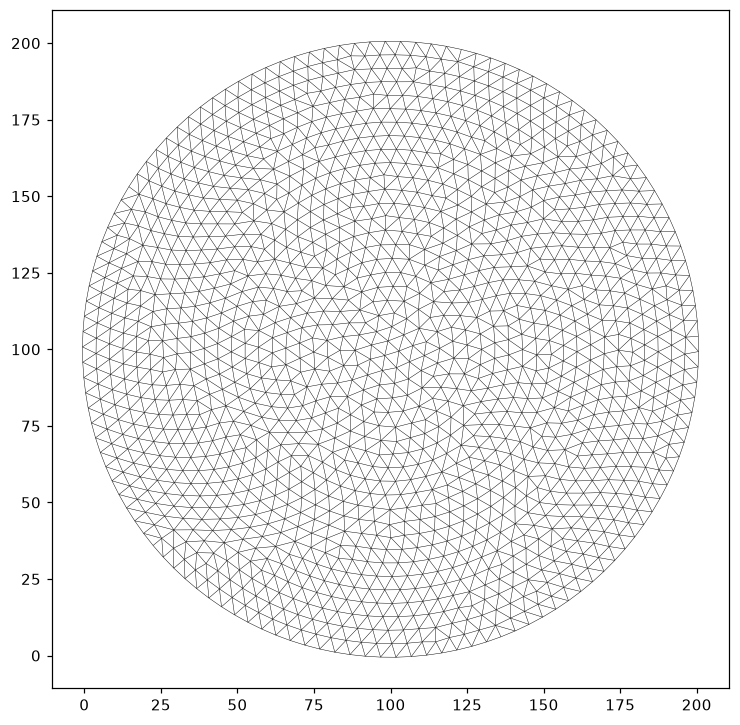

In [10]:
ds.plot_outline()
show()

## Mapping the real results

We map two summary fields that need no time selection: `max_H`, the peak water level reached anywhere during the run, and `ZB`, the underlying bed elevation. Together they tell the flood story - where water went and the terrain beneath it.

## Mapping the real results

These files carry genuine model output, so the point of the package is to *see* it. `ds.plot(variable, cmap=..., colorbar=..., title=...)` colours each face by its value and routes through cleopatra (reached via pyramids) for the actual rendering.

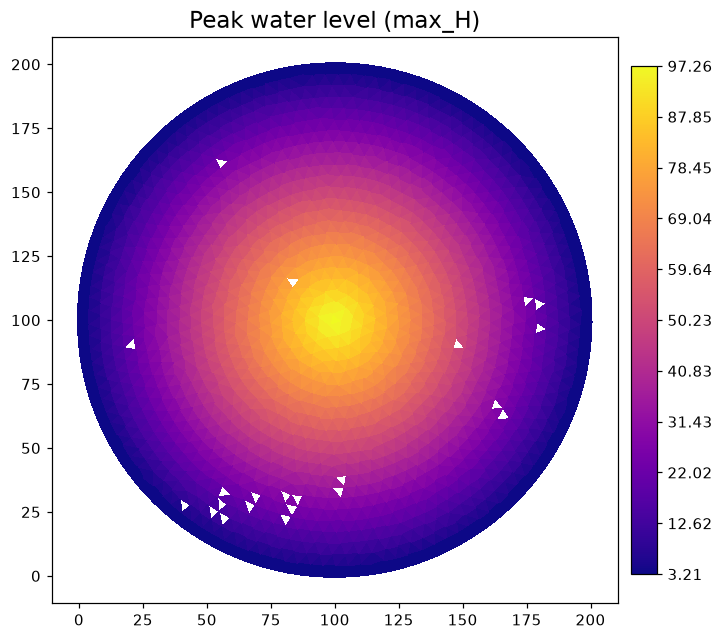

In [11]:
ds.plot("max_H", cmap="plasma", colorbar=True, title="Peak water level (max_H)")
show()

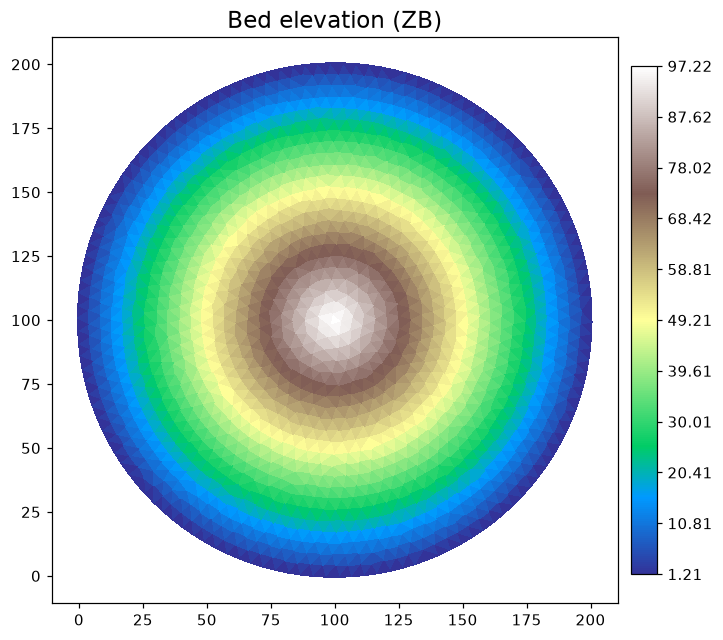

In [12]:
ds.plot("ZB", cmap="terrain", colorbar=True, title="Bed elevation (ZB)")
show()

## From mesh to GIS

A `UgridDataset` is not a dead end - it converts into the vector and raster types the rest of a GIS workflow expects. Everything below is reached through pyramids; this package only supplies the file-format driver that built the mesh.

### Faces as vector polygons

`to_geodataframe(variable_name=...)` turns every face into a polygon row carrying that variable's value - a standard GeoPandas `GeoDataFrame` you can join, filter, or export.

In [13]:
gdf = ds.to_geodataframe(variable_name="max_H")
print("rows:", len(gdf), " columns:", list(gdf.columns), " crs:", gdf.crs)
gdf.head()

rows: 2866  columns: ['max_H', 'geometry']  crs: None


,max_H,geometry
0,3.212479,"POLYGON ((19.36256 39.8936, 22.46044 35.94882,..."
1,3.212720,"POLYGON ((25.75109 32.16335, 29.18528 35.06804..."
2,3.212404,"POLYGON ((29.18528 35.06804, 25.75109 32.16335..."
3,5.516877,"POLYGON ((29.24278 41.01716, 22.88029 42.68976..."
4,3.212687,"POLYGON ((25.75109 32.16335, 25.2713 38.28082,..."


Plotting that `GeoDataFrame` straight through GeoPandas (matplotlib under the hood) gives a choropleth of the same values, now as independent vector features.

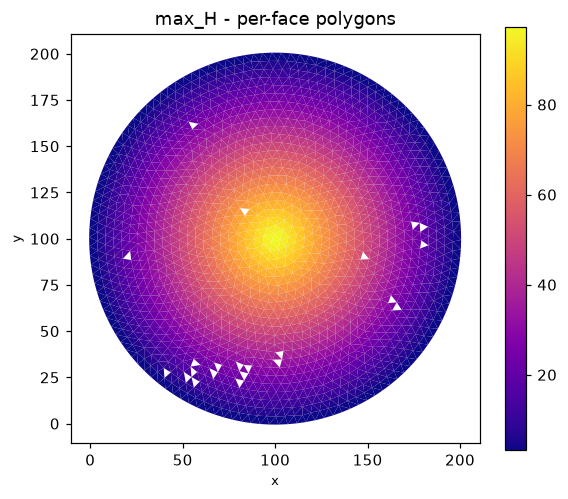

In [14]:
gdf.plot(column="max_H", cmap="plasma", legend=True, figsize=(6, 5))
plt.title("max_H - per-face polygons")
show()

### Dissolving into zones

`polygonize(variable)` merges neighbouring faces that share a value into larger polygons - handy for turning a noisy per-cell field into clean zones. It needs a single value per face, which is exactly what our working dataset holds.

dissolved polygons: 2842  columns: ['value', 'geometry']


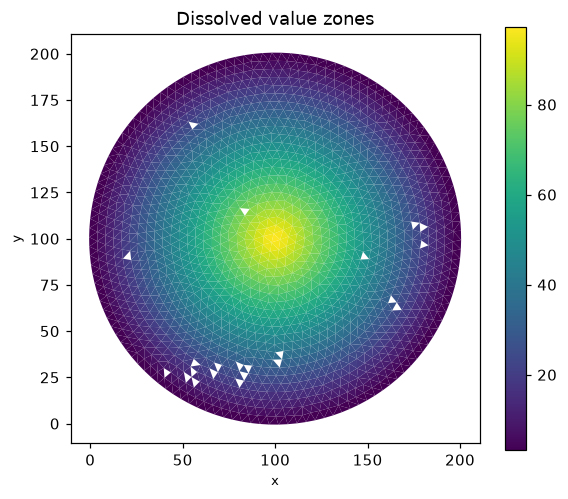

In [15]:
zones = ds.polygonize("max_H")
print("dissolved polygons:", len(zones), " columns:", list(zones.columns))
zones.plot(column="value", cmap="viridis", legend=True, figsize=(6, 5))
plt.title("Dissolved value zones")
show()

### Sampling at points

`sample(variable, x, y)` reads the value of the face that contains each query point. Here we probe the first few face centroids, so each query lands squarely inside a face.

In [16]:
cen = np.asarray(ds.mesh.face_centroids)
xs, ys = cen[0][:5], cen[1][:5]
vals = ds.sample("max_H", xs, ys)
for x, y, v in zip(xs, ys, np.asarray(vals)):
    print(f"({x:10.2f}, {y:10.2f}) -> {float(v):.4f}")

(     22.36,      38.04) -> 3.2125
(     26.74,      35.17) -> 3.2127
(     28.05,      31.93) -> 3.2124
(     25.80,      40.66) -> 5.5169
(     24.49,      35.46) -> 3.2127


### The mesh outline as one polygon

`bounding_polygon()` returns a single shapely polygon tracing the mesh's outer boundary - the model's wetted footprint, useful as a clip mask or extent reference.

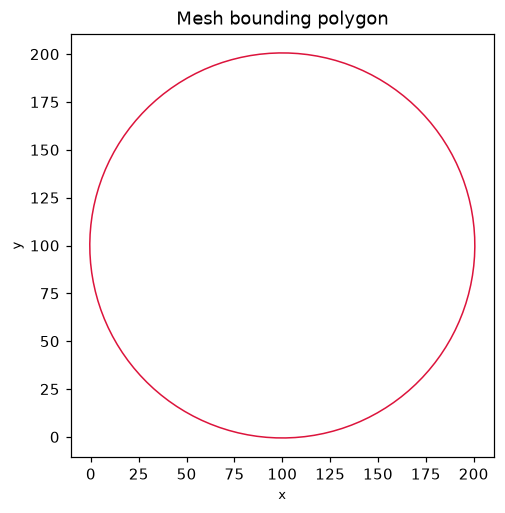

In [17]:
poly = ds.bounding_polygon()
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 5))
plt.title("Mesh bounding polygon")
show()

### Cropping to a sub-region

`subset_by_bounds(xmin, ymin, xmax, ymax)` returns a new, smaller `UgridDataset` holding only the faces inside the box - the same object type, so every operation above still applies. We derive a box from the mesh envelope so it works on any extent.

faces in full mesh: 2866  -> in subset: 718


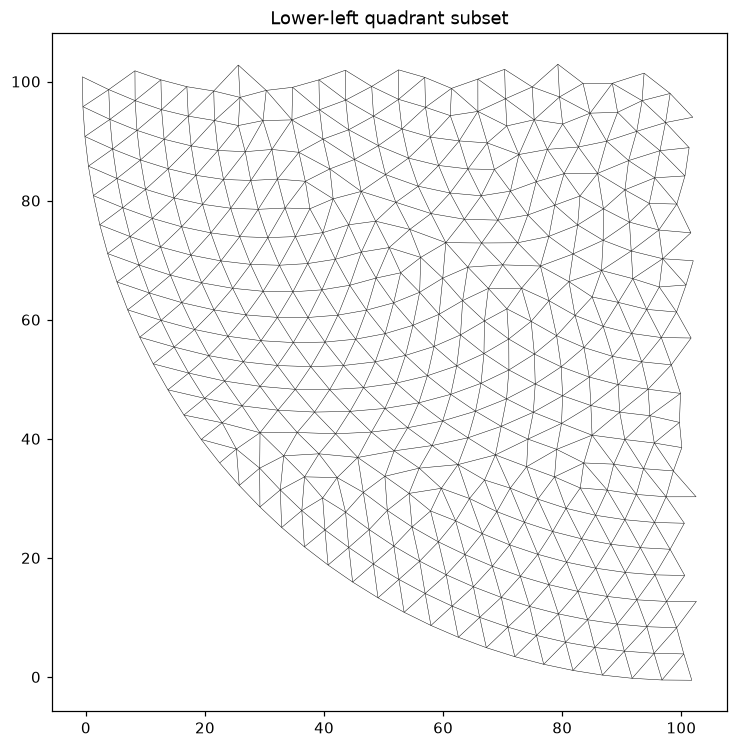

In [18]:
xmin, ymin, xmax, ymax = ds.bounds
mx, my = (xmin + xmax) / 2, (ymin + ymax) / 2
sub = ds.subset_by_bounds(xmin, ymin, mx, my)
print("faces in full mesh:", ds.n_face, " -> in subset:", sub.n_face)
sub.plot_outline()
plt.title("Lower-left quadrant subset")
show()

### Connectivity as a sparse graph

`sparse_adjacency()` exposes face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels each face by which connected piece of the mesh it belongs to - the entry points for graph algorithms over the grid.

In [19]:
adj = ds.sparse_adjacency()
print("adjacency:", adj.shape, " non-zeros:", adj.nnz)
labels = ds.connected_components()
print("connected components:", len(np.unique(np.asarray(labels))))

adjacency: (2866, 2866)  non-zeros: 8472
connected components: 1


### Circumcenters (triangular meshes)

This mesh is triangular, so `circumcenters()` is defined: it returns the circumcentre of every triangle - the natural dual-grid points used by finite-volume schemes.

In [20]:
cc = ds.circumcenters()
print("circumcenters:", np.asarray(cc).shape)
cc[:3]

circumcenters: (2866, 2)


array([[22.29528563, 39.00790761],
       [26.07226163, 35.26609218],
       [28.99882605, 31.80602579]])

### Self-contained rasterisation

`to_dataset(variable, cell_size=...)` samples the mesh onto a regular raster grid and returns a pyramids `Dataset`. Unlike `rasterize_like` / `regrid` - which need an existing reference grid and are therefore skipped here - this is self-contained: you only choose a cell size.

rasterised to:

 Dataset


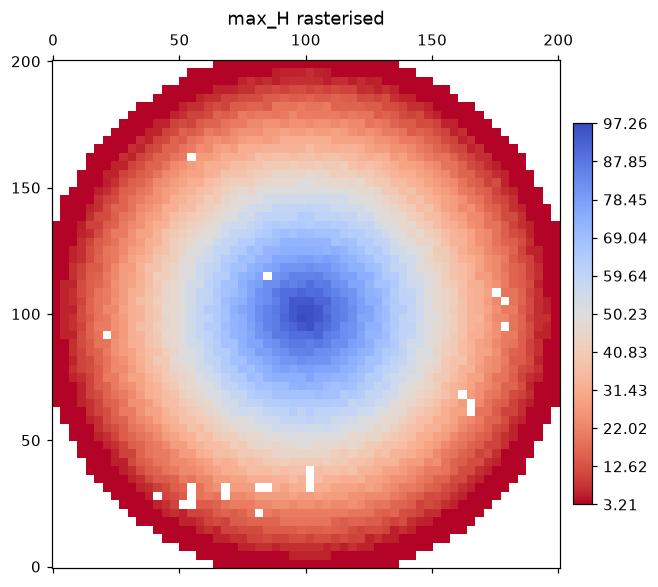

In [21]:
step_xy = (ds.bounds[2] - ds.bounds[0]) / 60
rast = ds.to_dataset("max_H", cell_size=step_xy)
print("rasterised to:", type(rast).__name__)
rast.plot()
plt.title("max_H rasterised")
show()

### Reprojection - skipped

`to_crs(...)` needs a *source* CRS to project from. This TUFLOW FV file stores no CRS, so `ds.crs` is `None`. With no source CRS, reprojection is undefined, so we skip it; assign a CRS first if your coordinates are georeferenced.

### Back to xarray

`to_xarray()` hands the whole dataset back as an `xarray.Dataset`, so you can drop into the full xarray ecosystem (time selection, resampling, NetCDF export) whenever you need it.

In [22]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)[:6]

('Dataset',
 ['mesh2d',
  'mesh2d_node_x',
  'mesh2d_node_y',
  'mesh2d_face_nodes',
  'mesh2d_face_x',
  'mesh2d_face_y'])

## Takeaway

TUFLOW FV gives pyramids-mesh a true triangular finite-volume mesh with a full variable set. Summary fields like `max_H` map directly (no timestep to choose), the triangular topology unlocks `circumcenters()`, and the same `GeoDataFrame` / polygonize / crop / rasterise operations apply unchanged. The driver parses TUFLOW's NetCDF layout; the mesh science stays in pyramids.